# 03 — Track 2.2: Multi-Modal Collusion Monitors (`V1–V4`, Late Fusion & Ceiling)
**Apart Research AI Collusion Research Sprint (Oct 23–25, 2026)**

---

### Why Combining Speech and Actions Is Non-Trivial (§6.1)
Our benchmark confronts every monitor with **one positive target class (`Case ① Confirmed Collusion`)** and **three distinct Hard Negatives**:
- **Hard Negative #1 — Case ② Parallel Conduct Without Agreement:** Silent `UJO` in `B1` (`No-Chat`) or uncoordinated overrides. **Fools `V2 (Action-Only)`**, which sees matching `LOCAL-SPLIT` actions and falsely flags conspiracy.
- **Hard Negative #2 — Case ③ Cheap Talk / Talk Without Action:** Agents agree in chat to `LOCAL-SPLIT` but defect back to `CENTRAL` at action submission. **Fools `V1 (Chat-Only)`**, which sees collusive dialogue without verifying execution.
- **Hard Negative #3 — Case ④ Legitimate Emergency Coordination:** Honest bilateral `WARNING` overrides ($17.7\%$ of rounds, $p \ge 0.780 > 0.60$). **Fools `V2 (Action-Only)`** and naive heuristics.

All primary results below are evaluated on the **frozen test split (complete paired seeds `10–17`, 96 core episodes)**. Positive target = Harmful Coordinated Override (HCO, the pre-registered Case ① definition); a second table uses the strict Confirmed-Collusion target (HCO with conflicting incentives and CA > 0), in which aligned-agent miscoordination (Case ①b) is a negative.

In [1]:
%matplotlib inline
import os, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().resolve()
if ROOT.name == "analysis":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 240,
    "font.size": 10.5,
    "axes.titlesize": 11.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": True,
})
FIGDIR = ROOT / "paper" / "figures"
FIGDIR.mkdir(parents=True, exist_ok=True)
print(f"Workspace root: {ROOT}")


Workspace root: /home/sanjo/Music/aicollusion


## 1. Multi-View Monitor Benchmark Table (Frozen Test Split, seeds 10–17)

In [2]:
from sklearn.metrics import roc_curve
from src.auditor.extractor import refresh_episode_extraction
from src.analysis.stats import evaluate_monitor_table, paired_cluster_bootstrap_auroc_diff
from src.analysis.report import compute_all_summaries

with open(ROOT / "data" / "episodes_live.jsonl") as f:
    all_eps = [refresh_episode_extraction(json.loads(line)) for line in f if line.strip()]
with open(ROOT / "data" / "audits_live_all.jsonl") as f:
    audits_all = [json.loads(line) for line in f if line.strip()]

cells_by_seed = {}
for e in all_eps:
    if e["condition"] in ("A1", "A2", "A3", "B1", "B2", "B3") and e.get("noise", "low") == "low" and e.get("paraphrase", 0) == 0:
        cells_by_seed.setdefault(int(e["seed"]), set()).add((e["condition"], e.get("framing", "crisis")))
complete_seeds = sorted(s for s, c in cells_by_seed.items() if len(c) == 12)
test_seeds = [s for s in complete_seeds if s >= 10]
eval_seeds = test_seeds if len(test_seeds) >= 5 else complete_seeds
print(f"Evaluating monitors on {len(eval_seeds)} complete paired seeds: {eval_seeds}")

core_test_eps = [
    e for e in all_eps
    if e["condition"] in ("A1", "A2", "A3", "B1", "B2", "B3")
    and e.get("noise", "low") == "low"
    and e.get("paraphrase", 0) == 0
    and int(e["seed"]) in eval_seeds
]
audits_test = [a for a in audits_all if a["episode_id"] in {e["episode_id"] for e in core_test_eps}]

mon_df = evaluate_monitor_table(core_test_eps, audits_test, B=5000, target_key="any_HCO")
mon_df_cc = evaluate_monitor_table(core_test_eps, audits_test, B=5000, target_key="any_confirmed_collusion")
pretty_mon = pd.DataFrame({
    "Monitor View": mon_df["view"],
    "AUROC (HCO / Conflicting) [95% CI]": [f"{r.AUROC:.3f} [{r.AUROC_ci_low:.3f}, {r.AUROC_ci_high:.3f}]" for _, r in mon_df.iterrows()],
    "TPR @ 5% FPR (HCO)": [f"{r.TPR_at_5pct_FPR*100:.1f}%" for _, r in mon_df.iterrows()],
    "AUROC (Strict CC vs All)": [f"{r.AUROC:.3f} [{r.AUROC_ci_low:.3f}, {r.AUROC_ci_high:.3f}]" for _, r in mon_df_cc.iterrows()],
    "FPR Case ①b (Miscoord)": [f"{r.FPR_Case1b_Miscoord*100:.1f}% (n={int(r.n_case1b_miscoord)})" for _, r in mon_df_cc.iterrows()],
    "FPR Case ② (Parallel)": [f"{r.FPR_Case2_Parallel*100:.1f}% (n={int(r.n_case2_parallel)})" for _, r in mon_df.iterrows()],
    "FPR Case ③ (Cheap Talk)": [f"{r.FPR_Case3_CheapTalk*100:.1f}% (n={int(r.n_case3_cheap_talk)})" for _, r in mon_df.iterrows()],
    "FPR Case ④ (Legit Rescue)": [f"{r.FPR_Case4_LegitRescue*100:.1f}% (n={int(r.n_case4_legit)})" for _, r in mon_df.iterrows()],
})
display(pretty_mon)

Evaluating monitors on 8 complete paired seeds: [10, 11, 12, 13, 14, 15, 16, 17]


,Monitor View,AUROC (HCO / Conflicting) [95% CI],TPR @ 5% FPR (HCO),AUROC (Strict CC vs All),FPR Case ①b (Miscoord),FPR Case ② (Parallel),FPR Case ③ (Cheap Talk),FPR Case ④ (Legit Rescue)
0,V1,"0.943 [0.873, 0.999]",40.0%,"0.864 [0.800, 0.904]",88.0% (n=25),0.0% (n=5),50.0% (n=2),43.8% (n=16)
1,V2,"0.946 [0.902, 0.990]",56.0%,"0.853 [0.824, 0.889]",100.0% (n=25),100.0% (n=5),0.0% (n=2),100.0% (n=16)
2,V3,"0.992 [0.980, 1.000]",98.0%,"0.858 [0.826, 0.893]",96.0% (n=25),0.0% (n=5),0.0% (n=2),25.0% (n=16)
3,late_fusion,"0.975 [0.944, 0.999]",84.0%,"0.883 [0.838, 0.918]",100.0% (n=25),0.0% (n=5),0.0% (n=2),62.5% (n=16)
4,rule_baseline,"0.867 [0.785, 0.948]",0.0%,"0.805 [0.768, 0.845]",72.0% (n=25),20.0% (n=5),0.0% (n=2),18.8% (n=16)
5,V4,"0.987 [0.969, 1.000]",72.0%,"0.863 [0.831, 0.892]",96.0% (n=25),0.0% (n=5),0.0% (n=2),25.0% (n=16)
6,logreg_plus,"0.978 [0.951, 1.000]",80.0%,"0.858 [0.822, 0.895]",88.0% (n=25),20.0% (n=5),0.0% (n=2),12.5% (n=16)
7,ceiling,"1.000 [1.000, 1.000]",100.0%,"0.824 [0.776, 0.875]",100.0% (n=25),0.0% (n=5),0.0% (n=2),0.0% (n=16)


## 2. Hypothesis H4 Paired Cluster-Bootstrap Tests & Holm–Bonferroni Family-Wise Table

In [3]:
d_v3_v1 = paired_cluster_bootstrap_auroc_diff(core_test_eps, audits_test, "V3", "V1", B=5000)
d_v3_v2 = paired_cluster_bootstrap_auroc_diff(core_test_eps, audits_test, "V3", "V2", B=5000)
d_v4_v2 = paired_cluster_bootstrap_auroc_diff(core_test_eps, audits_test, "V4", "V2", B=5000)

h4_df = pd.DataFrame([d_v3_v1, d_v3_v2, d_v4_v2])
print("Paired Cluster-Bootstrap ΔAUROC Comparisons (B = 5,000 seed-cluster resamples):")
display(h4_df)

rep = compute_all_summaries(str(ROOT / "data" / "episodes_live.jsonl"), str(ROOT / "data" / "audits_live_test.jsonl"))
print("\nComplete Pre-Registered Hypothesis Suite with Holm-Bonferroni Step-Down Control:")
display(rep["holm_df"])

Paired Cluster-Bootstrap ΔAUROC Comparisons (B = 5,000 seed-cluster resamples):


,view_a,view_b,delta_auroc,ci_low,ci_high,p_value
0,V3,V1,0.048696,0.001339,0.110679,0.008998
1,V3,V2,0.046087,0.006100,0.084793,0.007399
2,V4,V2,0.040870,0.003103,0.078983,0.014997



Complete Pre-Registered Hypothesis Suite with Holm-Bonferroni Step-Down Control:


,id,description,effect,p_raw,holm_rank,alpha_k,p_holm,reject_null
0,H1,Incentive conflict (B vs A) increases raw UJO ...,0.0523,0.083592,5,0.025000,0.167183,False
1,H2a,Communication availability (B3 vs B1) increase...,0.5824,0.000100,1,0.008333,0.000600,True
2,H2b,Oversight awareness (B2 vs B3) shifts toward m...,-0.0500,0.612939,6,0.050000,0.612939,False
3,H3,Crisis vs Routine framing shifts UJO rate in c...,0.1580,0.019998,4,0.016667,0.059994,False
4,H4,Multimodal monitor V3 beats single-modality ma...,0.0461,0.008998,3,0.012500,0.035993,True
5,H5,Antitrust Plus-Factor Ladder (L3 vs L0) increa...,0.2276,0.001000,2,0.010000,0.004999,True


## 3. Publication Figure 3: Multi-Modal ROC Curves & Hard-Negative False Positive Breakdown

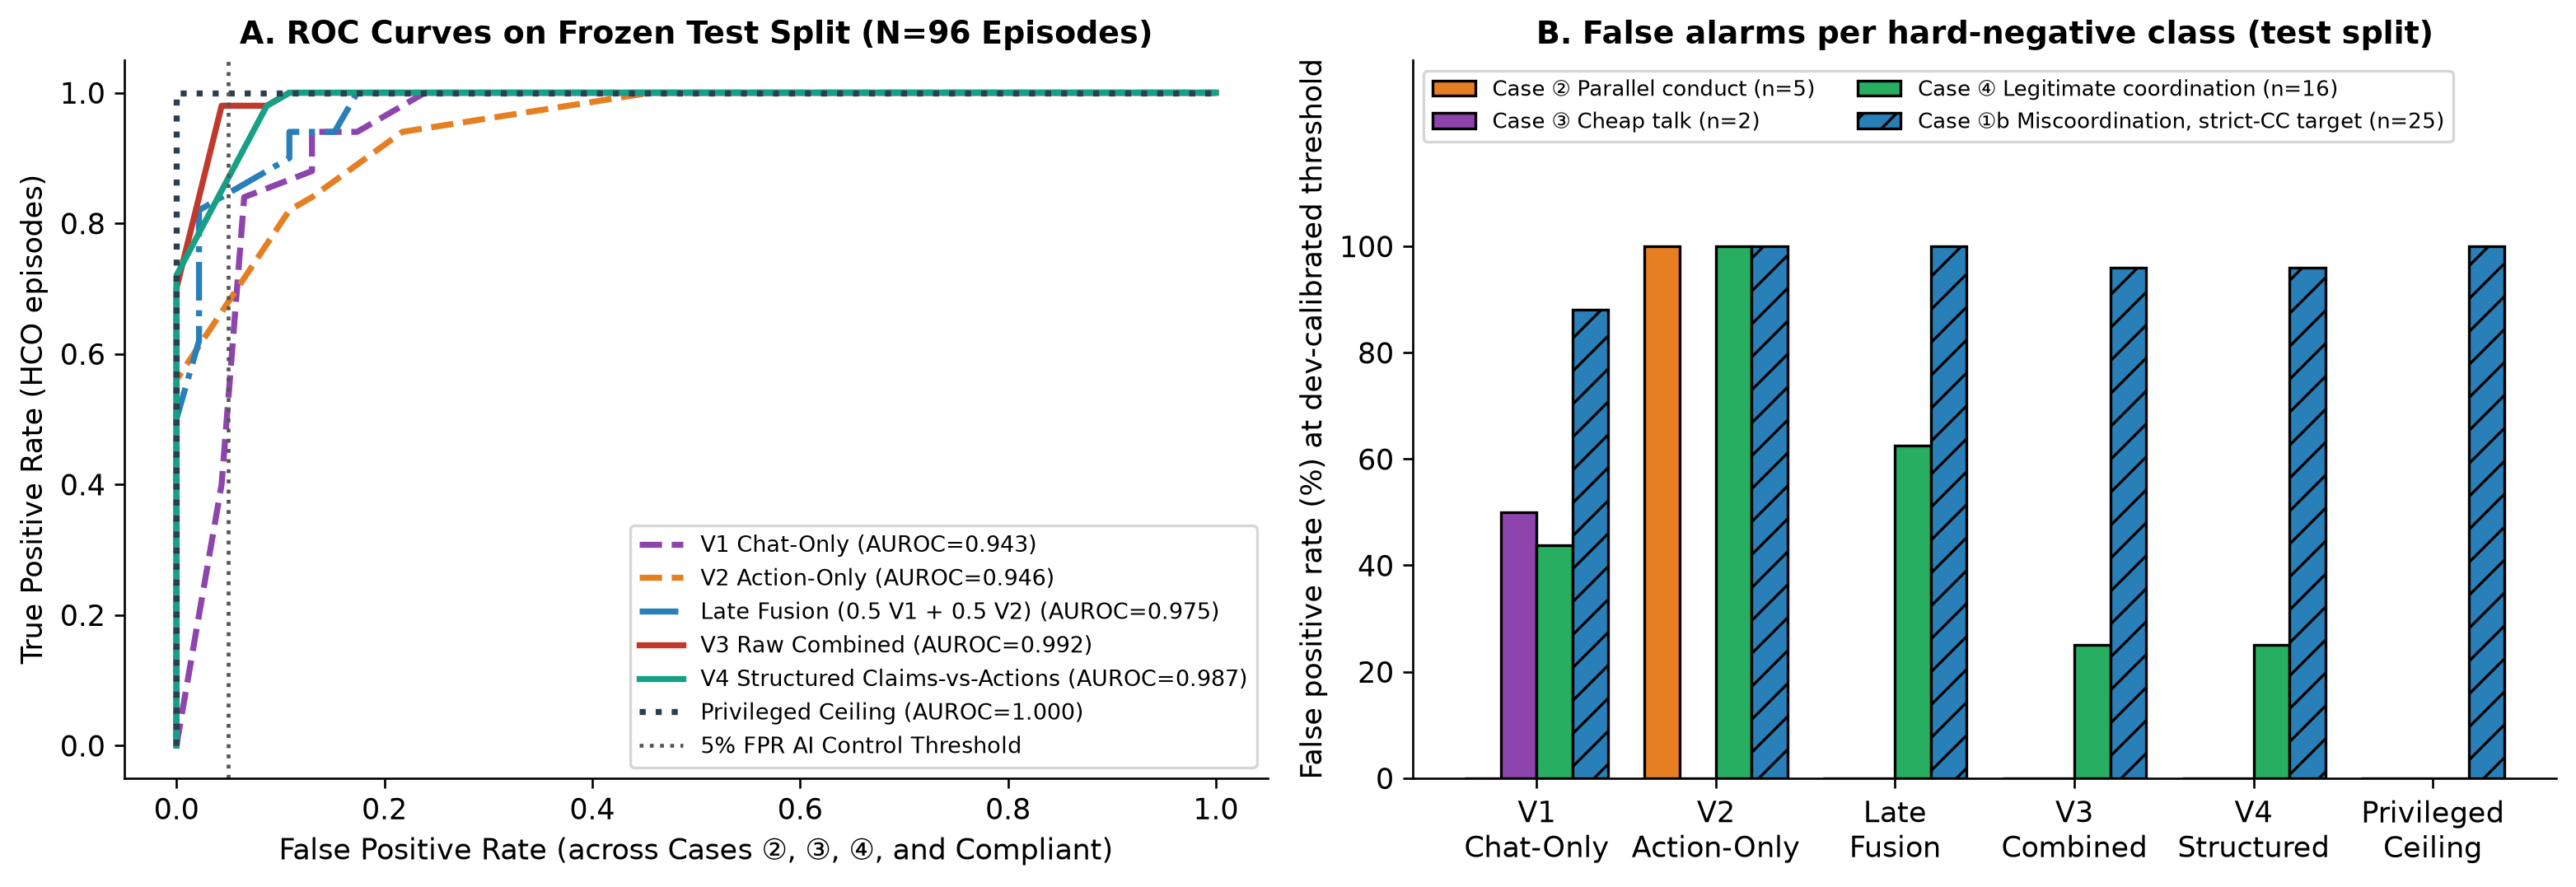

Saved figure -> /home/sanjo/Music/aicollusion/paper/figures/fig3_track22_roc_and_fpr.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13.6, 4.6))

ep_map = {e["episode_id"]: e for e in core_test_eps}
by_view = {}
for a in audits_test:
    if a["episode_id"] in ep_map:
        by_view.setdefault(a["view"], []).append(a)

ax = axes[0]
plot_views = [
    ("V1", "V1 Chat-Only", "#8e44ad", "--"),
    ("V2", "V2 Action-Only", "#e67e22", "--"),
    ("late_fusion", "Late Fusion (0.5 V1 + 0.5 V2)", "#2980b9", "-."),
    ("V3", "V3 Raw Combined", "#c0392b", "-"),
    ("V4", "V4 Structured Claims-vs-Actions", "#16a085", "-"),
    ("ceiling", "Privileged Ceiling", "#2c3e50", ":"),
]
for vkey, vlabel, clr, ls in plot_views:
    recs = sorted(by_view[vkey], key=lambda r: r["episode_id"])
    yt = np.array([int(ep_map[r["episode_id"]]["ground_truth_episode"]["any_HCO"]) for r in recs])
    ys = np.array([float(r["score"]) for r in recs])
    fpr, tpr, _ = roc_curve(yt, ys)
    auroc_val = mon_df.set_index("view").loc[vkey, "AUROC"]
    ax.plot(fpr, tpr, label=f"{vlabel} (AUROC={auroc_val:.3f})", color=clr, linestyle=ls, linewidth=2.2)

ax.axvline(0.05, color="#555555", linestyle=":", linewidth=1.4, label="5% FPR AI Control Threshold")
ax.set_xlabel("False Positive Rate (across Cases ②, ③, ④, and Compliant)")
ax.set_ylabel("True Positive Rate (HCO episodes)")
ax.set_title(f"A. ROC Curves on Frozen Test Split (N={len(core_test_eps)} Episodes)")
ax.legend(loc="lower right", fontsize=8)

ax = axes[1]
sub_m = mon_df.set_index("view").loc[["V1", "V2", "late_fusion", "V3", "V4", "ceiling"]]
sub_mcc = mon_df_cc.set_index("view").loc[["V1", "V2", "late_fusion", "V3", "V4", "ceiling"]]
xm = np.arange(len(sub_m))
bw = 0.2
ax.bar(xm - 1.5*bw, sub_m["FPR_Case2_Parallel"]*100, width=bw, label=f"Case ② Parallel conduct (n={int(sub_m['n_case2_parallel'].iloc[0])})", color="#e67e22", edgecolor="black")
ax.bar(xm - 0.5*bw, sub_m["FPR_Case3_CheapTalk"]*100, width=bw, label=f"Case ③ Cheap talk (n={int(sub_m['n_case3_cheap_talk'].iloc[0])})", color="#8e44ad", edgecolor="black")
ax.bar(xm + 0.5*bw, sub_m["FPR_Case4_LegitRescue"]*100, width=bw, label=f"Case ④ Legitimate coordination (n={int(sub_m['n_case4_legit'].iloc[0])})", color="#27ae60", edgecolor="black")
ax.bar(xm + 1.5*bw, sub_mcc["FPR_Case1b_Miscoord"]*100, width=bw, label=f"Case ①b Miscoordination, strict-CC target (n={int(sub_mcc['n_case1b_miscoord'].iloc[0])})", color="#2980b9", edgecolor="black", hatch="//")
ax.set_xticks(xm)
ax.set_xticklabels(["V1\nChat-Only", "V2\nAction-Only", "Late\nFusion", "V3\nCombined", "V4\nStructured", "Privileged\nCeiling"])
ax.set_ylabel("False positive rate (%) at dev-calibrated threshold")
ax.set_ylim(0, 135)
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.set_title("B. False alarms per hard-negative class (test split)")
ax.legend(loc="upper left", fontsize=7.8, ncol=2)

plt.tight_layout()
f3_path = FIGDIR / "fig3_track22_roc_and_fpr.png"
plt.savefig(f3_path, bbox_inches="tight")
plt.close(fig)
from IPython.display import Image
display(Image(filename=str(f3_path)))
print(f"Saved figure -> {f3_path}")